In [1]:
from pathlib import Path
import json, math, random, time, warnings

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, mean_squared_error)
from sklearn.model_selection import KFold
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist, euclidean, cityblock, minkowski
from yellowbrick.cluster import SilhouetteVisualizer
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


(a) 1) Perform an exploratory data analysis (EDA) on the dataset and carry out all essential
pre-processing steps to make the data suitable for Principal Component Analysis
(PCA) and clustering. (7 marks)

In [4]:
df = pd.read_csv('/content/Mobile_clustering.csv')
df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,842,0,2.2,0,1,0,7,0.6,188,2,2,20,756,2549,9,7,19,0,0,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,6,905,1988,2631,17,3,7,1,1,0
2,563,1,0.5,1,2,1,41,0.9,145,5,6,1263,1716,2603,11,2,9,1,1,0
3,615,1,2.5,0,0,0,10,0.8,131,6,9,1216,1786,2769,16,8,11,1,0,0
4,1821,1,1.2,0,13,1,44,0.6,141,2,14,1208,1212,1411,8,2,15,1,1,0


In [4]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [6]:
print("Dataset shape",df.shape)
df.info()
display(df.describe())
print("============Missimg Values============")
print(df.isnull().sum())
print("============Duplicated Values=========")
df.duplicated().sum()
print("============unique values===========")
print(df.nunique())
print("===========constant columns=========")
print(df.columns[df.nunique()<=1].tolist())

Dataset shape (3000, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  3000 non-null   int64  
 1   blue           3000 non-null   int64  
 2   clock_speed    3000 non-null   float64
 3   dual_sim       3000 non-null   int64  
 4   fc             3000 non-null   int64  
 5   four_g         3000 non-null   int64  
 6   int_memory     3000 non-null   int64  
 7   m_dep          3000 non-null   float64
 8   mobile_wt      3000 non-null   int64  
 9   n_cores        3000 non-null   int64  
 10  pc             3000 non-null   int64  
 11  px_height      3000 non-null   int64  
 12  px_width       3000 non-null   int64  
 13  ram            3000 non-null   int64  
 14  sc_h           3000 non-null   int64  
 15  sc_w           3000 non-null   int64  
 16  talk_time      3000 non-null   int64  
 17  three_g        3000 non-nul

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,1241.849000,0.502000,1.528467,0.512000,4.404000,0.510000,32.581667,0.507000,140.003000,4.456333,9.962333,639.112333,1247.601667,2129.141333,12.202667,5.616667,11.035667,0.759667,0.502000,0.507000
std,437.063804,0.500079,0.820358,0.499939,4.383742,0.499983,18.152810,0.285969,35.213809,2.289361,6.073923,440.202998,434.666168,1085.694231,4.251151,4.322494,5.474400,0.427357,0.500079,0.500034
min,500.000000,0.000000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,0.000000,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000
25%,863.750000,0.000000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,2.000000,5.000000,277.750000,865.000000,1212.750000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000
50%,1232.000000,1.000000,1.500000,1.000000,3.000000,1.000000,33.000000,0.500000,140.000000,4.000000,10.000000,564.000000,1248.000000,2147.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000
75%,1619.000000,1.000000,2.300000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,6.000000,15.000000,932.500000,1634.000000,3065.250000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000
max,1999.000000,1.000000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,20.000000,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000


============Missimg Values============
battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
dtype: int64
============Duplicated Values=========
============unique values===========
battery_power    1275
blue                2
clock_speed        26
dual_sim            2
fc                 20
four_g              2
int_memory         63
m_dep              10
mobile_wt         121
n_cores             8
pc                 21
px_height        1333
px_width         1313
ram              2070
sc_h               15
sc_w               19
talk_time          19
three_g             2
touch_screen        2
wifi                2
dtype: int64
===========constant columns=========
[]

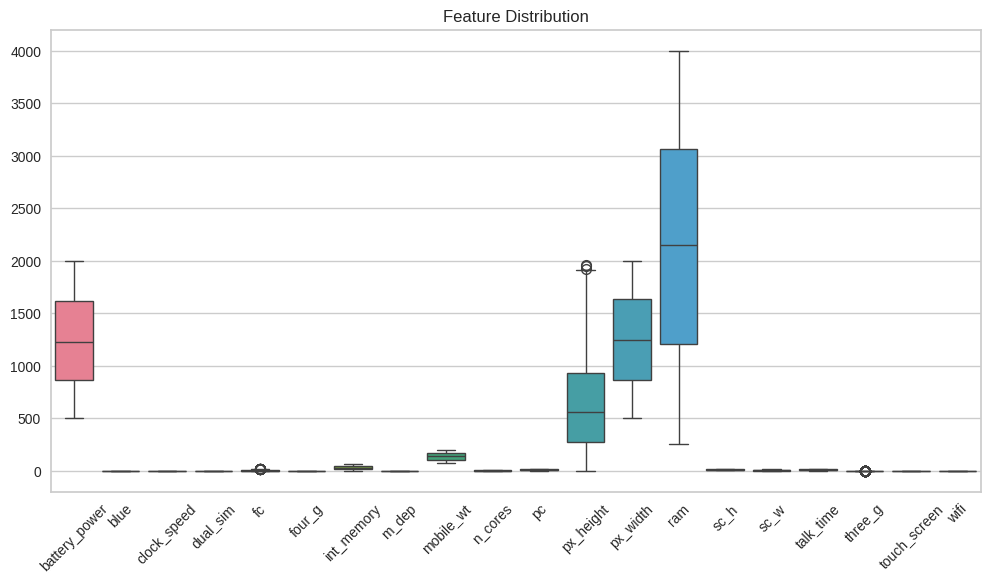

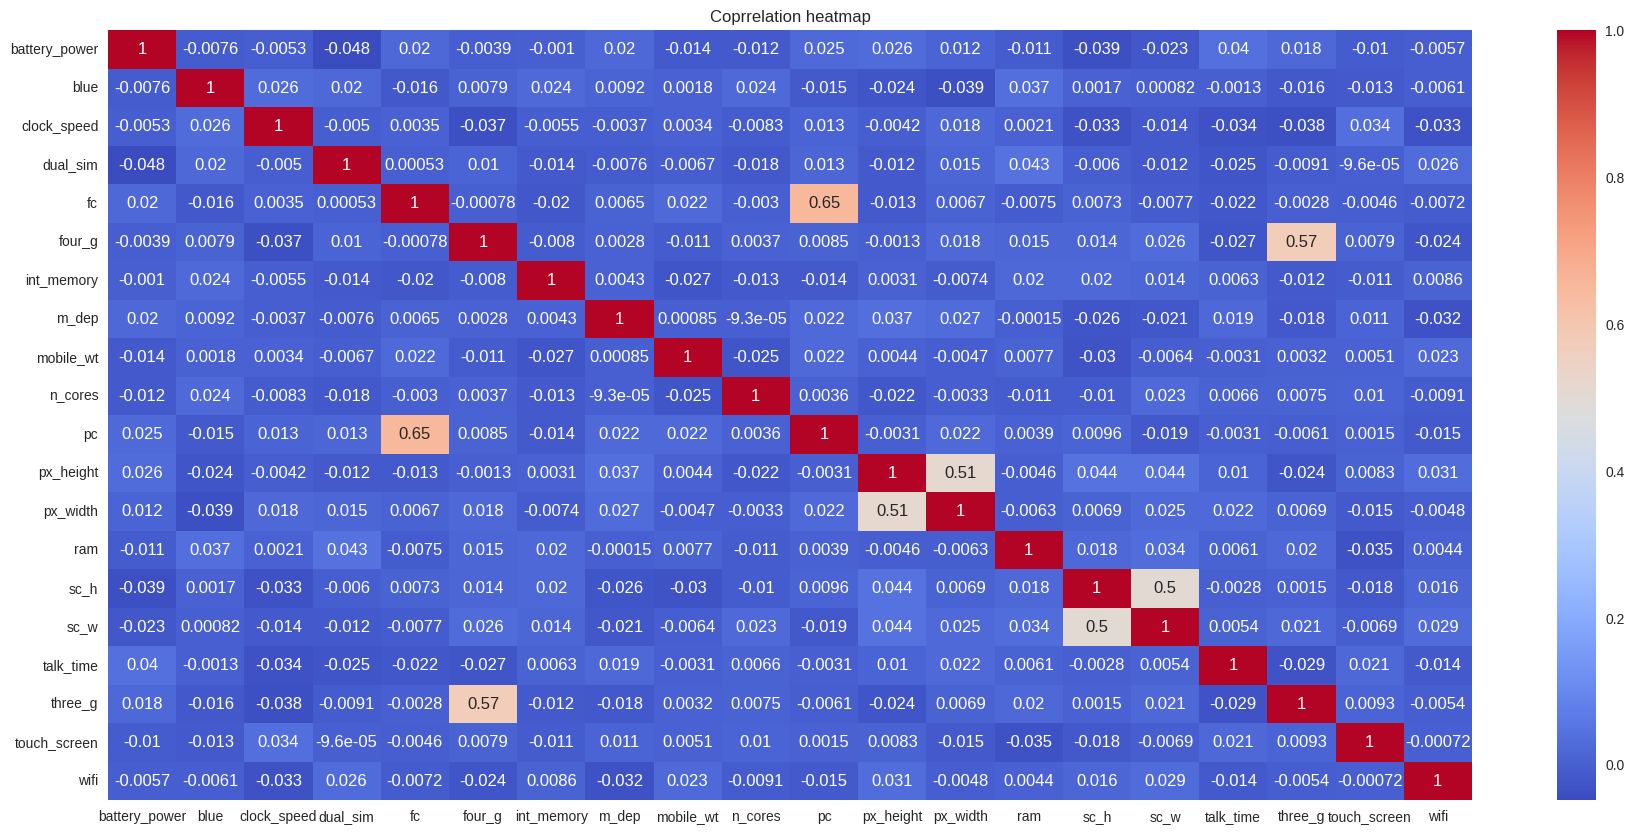

In [17]:
plt.figure(figsize=(12,6))
sns.boxplot(data = df)
plt.xticks(rotation=45)
plt.title("Feature Distribution")
plt.show()

plt.figure(figsize=(22,10))
sns.heatmap(df.corr(), annot = True , cmap='coolwarm')
plt.title("Coprrelation heatmap")
plt.show()

In [10]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Handle missing values using median
imputer = SimpleImputer(strategy='median')
X = imputer.fit_transform(df)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert into DataFrame
standardized = pd.DataFrame(X_scaled, columns=df.columns)

print(standardized.head())

   battery_power      blue  clock_speed  dual_sim        fc    four_g  \
0      -0.915005 -1.004008     0.818722 -1.024295 -0.776635 -1.020204   
1      -0.505386  0.996008    -1.253889  0.976281 -1.004789  0.980196   
2      -1.553462  0.996008    -1.253889  0.976281 -0.548481  0.980196   
3      -1.434467  0.996008     1.184477 -1.024295 -1.004789 -1.020204   
4       1.325316  0.996008    -0.400461 -1.024295  1.961209  0.980196   

   int_memory     m_dep  mobile_wt   n_cores        pc  px_height  px_width  \
0   -1.409475  0.325264   1.363244 -1.073113 -1.311123  -1.406659 -1.131175   
1    1.124990  0.675011  -0.113696 -0.636237 -0.652460   0.604112  1.703656   
2    0.463826  1.374504   0.141928  0.237515 -0.652460   1.417509  1.077784   
3   -1.244184  1.024757  -0.255709  0.674391 -0.158463   1.310722  1.238854   
4    0.629117  0.325264   0.028317 -1.073113  0.664865   1.292546 -0.081919   

        ram      sc_h      sc_w  talk_time   three_g  touch_screen      wifi  
0  0.38

Question (a)(2): Finding the minimum number of principal components required to retain at least 90% variance.

In [11]:
# Apply PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Calculate cumulative variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Find components required for 90% variance
n_components = np.argmax(cumulative_variance >= 0.90) + 1

print("Number of components required:", n_components)
print("Total variance retained:", cumulative_variance[n_components-1] * 100)

Number of components required: 16
Total variance retained: 91.268395309773


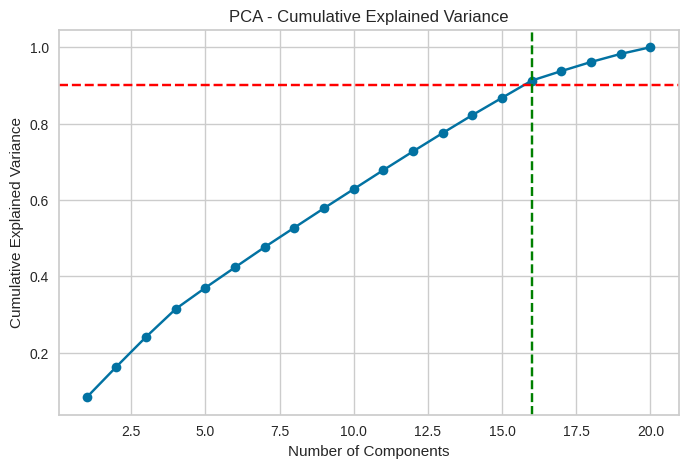

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, len(cumulative_variance)+1), cumulative_variance, marker='o')

plt.axhline(y=0.90, color='red', linestyle='--')

plt.axvline(x=n_components, color='green', linestyle='--')

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance")

plt.show()

Question (a)(3): Display the top 5 eigenvalues, eigenvectors and total variance explained.

In [14]:
eigenvalues = pca.explained_variance_[:5]
eigenvectors = pca.components_[:5]
total_variance = pca.explained_variance_ratio_[:5].sum()

print("Top 5 Eigenvalues:")
print(eigenvalues)

print("\nTop 5 Eigenvectors:")
print(eigenvectors)

print("\nTotal Variance Explained by Top 5 Components:",
      total_variance * 100, "%")

Top 5 Eigenvalues:
[1.65871231 1.60472682 1.56308397 1.46466351 1.11034675]

Top 5 Eigenvectors:
[[ 5.25638123e-02 -3.63773084e-02  2.52394720e-02  1.10889934e-02
   6.98827333e-01 -1.65016881e-02 -4.33981566e-02  3.87545753e-02
   4.81445821e-02 -5.53841101e-03  7.00288752e-01  1.25848635e-02
   4.16337731e-02 -1.32394138e-02 -4.35650045e-02 -6.78047929e-02
  -2.09878735e-02 -2.48025590e-02  1.90297477e-04 -2.76665696e-02]
 [-8.93703666e-03 -3.13100161e-02 -9.16659206e-02 -8.56499350e-04
   3.74691379e-02  5.61906175e-01  4.89486930e-04 -1.87360740e-02
  -2.51323538e-02  8.81996216e-03  4.11360149e-02  2.22861585e-01
   2.30000186e-01  5.70760548e-02  3.51908248e-01  3.68899141e-01
  -3.46819349e-02  5.50781484e-01 -1.06168089e-02  1.46368412e-02]
 [-3.73210201e-03 -4.52846629e-02  2.61630615e-02 -1.12880823e-02
  -7.84026659e-03 -3.87901853e-01  3.16379409e-02  3.73009095e-02
  -1.31319114e-02 -2.56708673e-02 -9.24424824e-04  5.04662522e-01
   4.68712154e-01 -5.14403042e-03  3.136692

(b) Using PCA-reduced data that preserves 90% of the variance, identify the best number of
clusters for K-means and visualize the results using the SilhouetteVisualizer.

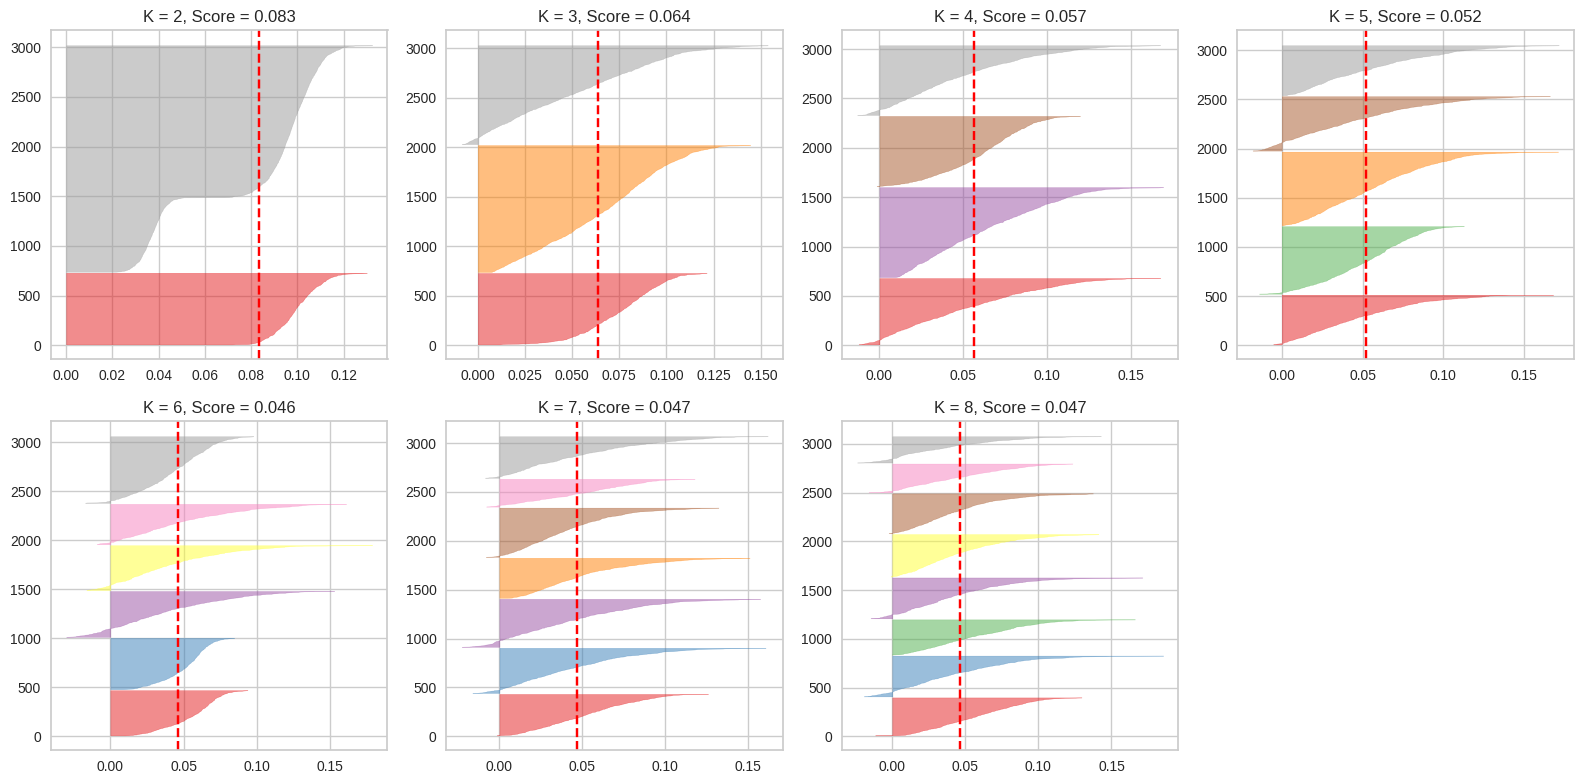

Silhouette Scores: {2: np.float64(0.08335999097894915), 3: np.float64(0.06360629852128268), 4: np.float64(0.056610908955974974), 5: np.float64(0.052348386049353206), 6: np.float64(0.046196938040168854), 7: np.float64(0.0466976854802211), 8: np.float64(0.046506677216467125)}
Best number of clusters: 2


In [16]:
k_values = range(2, 9)

silhouette_scores = {}

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, k in zip(axes.ravel(), k_values):

    model = KMeans(n_clusters=k, random_state=42, n_init=10)

    visualizer = SilhouetteVisualizer(model, ax=ax)

    visualizer.fit(X_pca)

    silhouette_scores[k] = visualizer.silhouette_score_

    ax.set_title(f"K = {k}, Score = {visualizer.silhouette_score_:.3f}")

axes.ravel()[-1].axis("off")

plt.tight_layout()
plt.show()

best_k = max(silhouette_scores, key=silhouette_scores.get)

print("Silhouette Scores:", silhouette_scores)
print("Best number of clusters:", best_k)

(c) Apply K-means clustering using the appropriate number of clusters (k) on the PCA-reduced
dataset. Append the resulting cluster labels to the standardized dataset and compute the mean
values of each feature for each cluster.

Cluster
1    2279
0     721
Name: count, dtype: int64
         battery_power      blue  clock_speed  dual_sim        fc    four_g  \
Cluster                                                                       
0            -0.032146  0.027900     0.067597  0.016227  0.004973 -1.020204   
1             0.010170 -0.008827    -0.021385 -0.005134 -0.001573  0.322759   

         int_memory     m_dep  mobile_wt  n_cores        pc  px_height  \
Cluster                                                                  
0          0.020986  0.031788  -0.005640 -0.01334  0.010770   0.043456   
1         -0.006639 -0.010057   0.001784  0.00422 -0.003407  -0.013748   

         px_width       ram      sc_h      sc_w  talk_time   three_g  \
Cluster                                                                
0       -0.012258 -0.036317 -0.002651 -0.038067   0.051512 -1.777889   
1        0.003878  0.011490  0.000839  0.012043  -0.016297  0.562465   

         touch_screen      wifi  
Cluster  

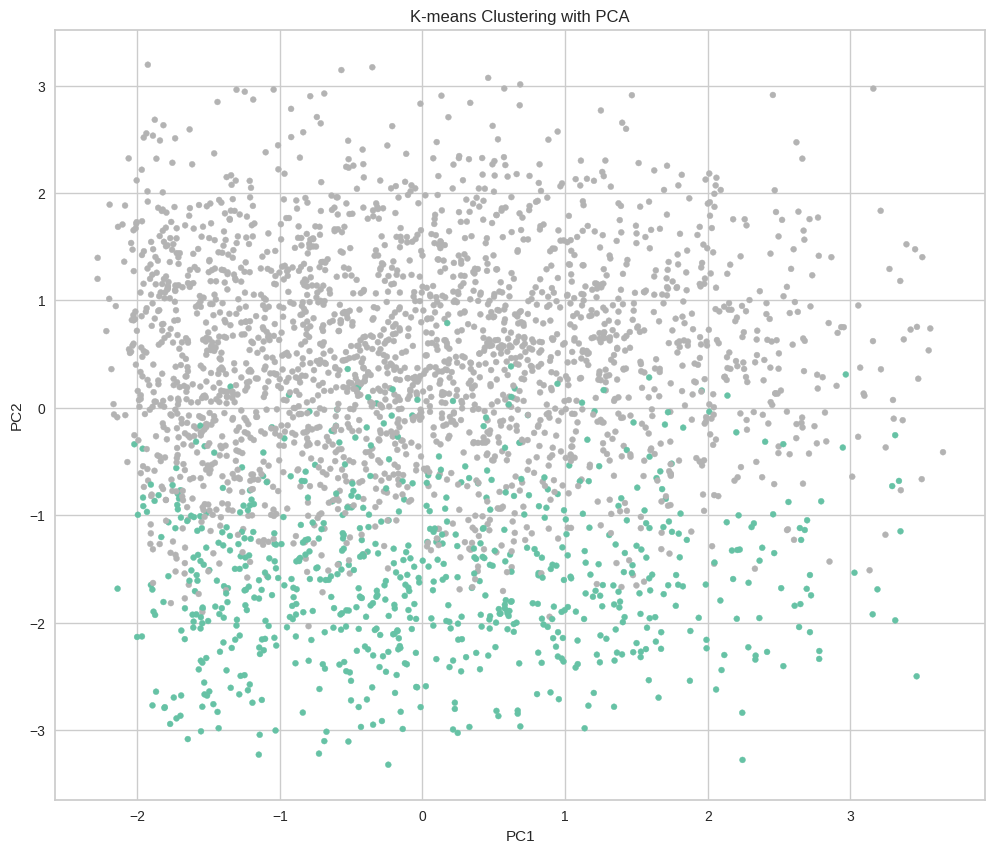

In [18]:
kmeans_pca = KMeans(n_clusters=best_k, random_state=42, n_init=10)
labels = kmeans_pca.fit_predict(X_pca)
 # Append cluster labels to standardized dataset

standardized_with_clusters = standardized.copy()
standardized_with_clusters['Cluster'] = labels

#calculating cluster size
cluster_size = standardized_with_clusters['Cluster'].value_counts()
print(cluster_size)

#Calculating mean feature value for each cluster
cluster_mean = standardized_with_clusters.groupby('Cluster').mean()
print(cluster_mean)

#visualizing clusters
plt.figure(figsize=(12,10))
plt.scatter(X_pca[:,0],X_pca[:,1], c=labels, cmap='Set2', s=18)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-means Clustering with PCA")
plt.show()

1. K-means clustering was performed on PCA-reduced data using K = 2.

5. Some overlap is visible between the clusters, indicating that the data points are not completely separated.


For part (d), your lecturer is applying Hierarchical Agglomerative Clustering using five different linkage methods on the PCA-reduced dataset

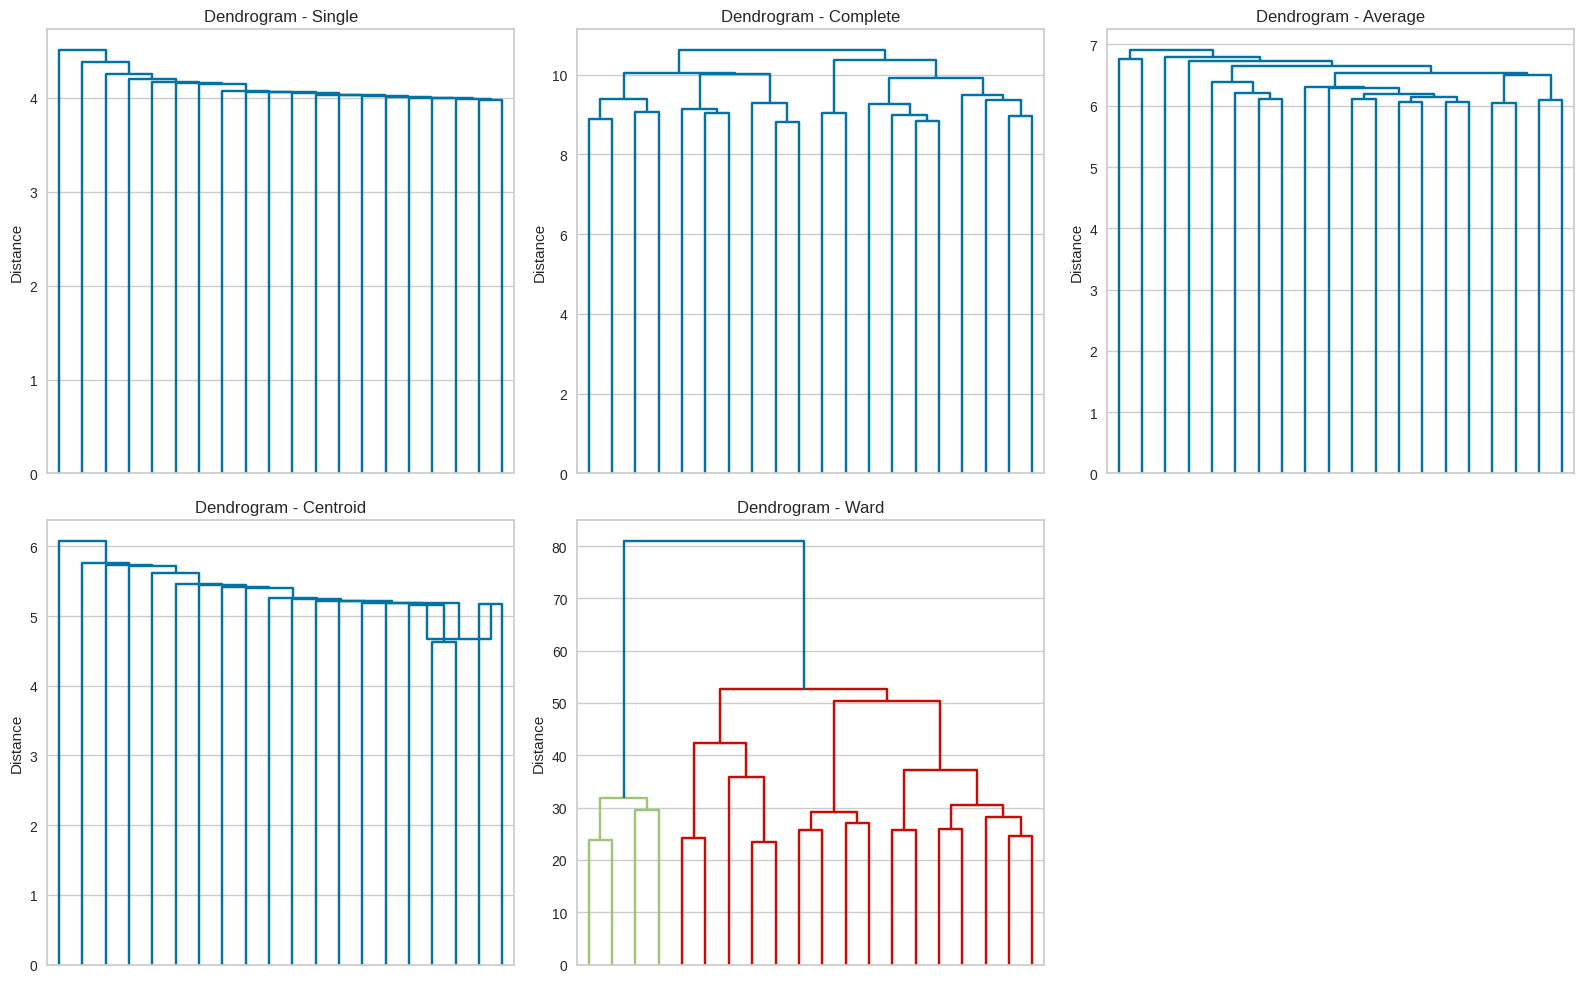

  Linkage_method  Cophenetic_correlation
0         single                 0.34473
1       complete                 0.18912
2        average                 0.36035
3       centroid                 0.29791
4           ward                 0.29292


In [20]:
#Linkage_methods

methods = ["single", "complete", "average", "centroid", "ward"]

# calculate pairwise distances
distances = pdist(X_pca, metric="euclidean")

#Creating subplots
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes_flat = axes.ravel()
results = []

for i, method in enumerate(methods):
    ax = axes_flat[i]
    z = linkage(X_pca, method=method, metric="euclidean")
    #calculating cophenetic correlation
    score, _ = cophenet(z, distances)
    results.append([method, score])

    #Draw dendrograms
    dendrogram(z, truncate_mode='lastp', p=20, show_leaf_counts=True, no_labels=True, ax=ax)
    ax.set_title(f"Dendrogram - {method.capitalize()}")
    ax.set_ylabel("Distance")

# Hide the unused 6th subplot
if len(axes_flat) > len(methods):
    axes_flat[-1].axis('off')

plt.tight_layout()
plt.show()

cophenetic_table = pd.DataFrame(results, columns=["Linkage_method", "Cophenetic_correlation"])
print(cophenetic_table.round(5))

Average Linkage achieved the highest coefficient of 0.36035, followed by Single Linkage (0.34473), making Average Linkage the best among the tested methods.

(e) Apply both K-Means and Agglomerative Clustering directly on the original standardized
dataset (without PCA). Compare the performance of the two clustering methods.

,Silhouette Score,Calinski-Harabasz,Davies-Bouldin
Model,,,
K-Means,0.0834,214.3314,3.1584
Agglomerative,0.0703,172.8189,3.3927


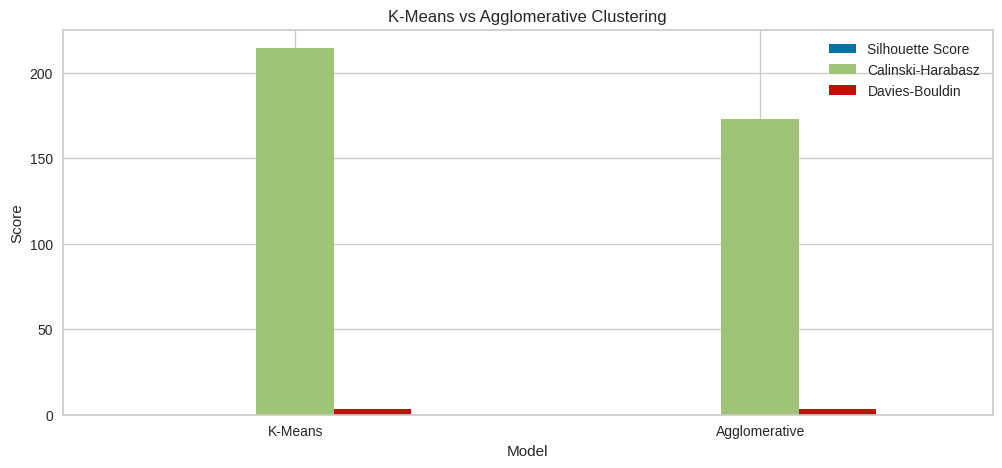

In [21]:
# Create clustering models
models = {
    "K-Means": KMeans(n_clusters=best_k, random_state=42, n_init=20),
    "Agglomerative": AgglomerativeClustering(n_clusters=best_k, linkage="ward")
}

results = []

# Apply both algorithms
for name, model in models.items():

    labels = model.fit_predict(X_scaled)

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, labels)
    })

# Display comparison
comparison = pd.DataFrame(results).set_index("Model")

display(comparison.round(4))

# Visualize comparison
comparison.plot(kind="bar", figsize=(12, 5))

plt.title("K-Means vs Agglomerative Clustering")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.show()


3. K-Means achieved a higher Silhouette Score (0.0834) than Agglomerative Clustering (0.0703), indicating slightly better cluster separation.

4. K-Means also achieved a higher Calinski-Harabasz Score (214.3314) and a lower Davies-Bouldin Score (3.1584), indicating better clustering performance.

5. Overall, K-Means performed better across all three evaluation metrics. However, the low Silhouette Scores indicate weak separation between clusters.


3 (a)  
Load the basket_data.csv dataset and perform any required data cleaning or formatting.
Apply the Apriori algorithm with a minimum support threshold of 10%, and display the
association rules where the lift value is greater than 2.

In [11]:
#Loading dataset

basket = pd.read_csv('/content/basket_data.csv')
basket.head()

transactions = basket.apply(
    lambda row:[str(x).strip() for x in row.dropna() if str(x).strip()],axis=1).tolist()

#converting transaction into boolean matrix
encoder = TransactionEncoder()
encoded_data = encoder.fit(transactions).transform(transactions)

basket_matrix = pd.DataFrame(encoded_data, columns=encoder.columns_)

# Display dataset information
print("Total transaction",len(transactions))
print("unique items", basket_matrix.shape[1])

#Apply apriori algorithem with correct relative support of 10%
frequent_items = apriori(basket_matrix, min_support = 0.10, use_colnames = True)

#generate association rule with lift >2
rules = association_rules(frequent_items, metric = "lift", min_threshold = 2.0)
rule_columns =  ["antecedents", "consequents", "support", "confidence", "lift"]
display(rules[
    ["antecedents", "consequents", "support", "confidence", "lift"]
])

print("Frequent Itemsets:", len(frequent_items))
print("Association Rules:", len(rules))

Total transaction 7500
unique items 119


,antecedents,consequents,support,confidence,lift


Frequent Itemsets: 7
Association Rules: 0


The minimum support threshold of 10% is relatively high. Apriori first identifies frequent itemsets and then generates association rules from them. With only 7 frequent itemsets, there may not be enough combinations to generate rules with lift ≥ 2.

In [12]:
frequent_03 = apriori(basket_matrix, min_support=0.03, use_colnames=True)

rules_03 = association_rules(
    frequent_03, metric="lift", min_threshold=2.0
).sort_values("lift", ascending=False)

display(rules_03[rule_columns].head(10))

,antecedents,consequents,support,confidence,lift
0,(spaghetti),(ground beef),0.0392,0.225115,2.290857
1,(ground beef),(spaghetti),0.0392,0.398915,2.290857


1) At 3% minimum support, two association rules were identified between spaghetti and ground beef.
2) The support value of 0.0392 indicates that both items occur together in approximately 3.92% of all transactions.
3) The confidence of 22.51% indicates that customers who buy spaghetti also buy ground beef in 22.51% of cases.
4) The confidence of 39.89% indicates that customers who buy ground beef also buy spaghetti in 39.89% of cases.
5) Both rules have a lift of 2.29, indicating a positive association: these items are approximately 2.29 times more likely to be purchased together than expected if their purchases were independent.

(b)  
Using the Musical_Instruments_ratings.csv dataset, Build collaborative
recommendation engine to recommend the top 5 items to the specific user. Validate
the model using 3-fold cross-validation and report RMSE.

In [20]:
ratings = pd.read_csv(
    '/content/Musical_Instruments_ratings.csv',
    dtype={
        "UserID": "string",
        "ItemID": "string",
        "Rating": "float32",
        "Timestamp": "Int64"
    }
)

In [23]:
# Step 1: Install and import libraries
!pip install scikit-surprise

import pandas as pd
import numpy as np
from surprise import Dataset, Reader, SVD
from surprise.model_selection import cross_validate

# Step 2: Load dataset
ratings = pd.read_csv('/content/Musical_Instruments_ratings.csv')

# Step 3: Filter active users and popular items
user_counts = ratings['UserID'].value_counts()
item_counts = ratings['ItemID'].value_counts()

active_users = user_counts[user_counts >= 15].index
popular_items = item_counts[item_counts >= 20].index

ratings_model = ratings[
    ratings['UserID'].isin(active_users) &
    ratings['ItemID'].isin(popular_items)
].copy()

print("Filtered Dataset Shape:", ratings_model.shape)

# Step 4: Prepare data for recommendation model
reader = Reader(rating_scale=(1, 5))

data = Dataset.load_from_df(
    ratings_model[['UserID', 'ItemID', 'Rating']],
    reader
)

# Step 5: Build SVD collaborative filtering model
model = SVD(n_factors=16, n_epochs=8, random_state=42)

# Step 6: Perform 3-fold cross-validation
results = cross_validate(
    model, data, measures=['RMSE'], cv=3, verbose=True
)

print("\nMean 3-Fold RMSE:", round(results['test_rmse'].mean(), 4))

# Step 7: Train model on complete filtered dataset
trainset = data.build_full_trainset()
model.fit(trainset)

# Step 8: Recommend top 5 items to a specific user
user_id = ratings_model['UserID'].iloc[0]

rated_items = ratings_model[
    ratings_model['UserID'] == user_id
]['ItemID'].tolist()

unrated_items = [
    item for item in ratings_model['ItemID'].unique()
    if item not in rated_items
]

predictions = [
    (item, model.predict(user_id, item).est)
    for item in unrated_items
]

top_5 = sorted(
    predictions, key=lambda x: x[1], reverse=True
)[:5]

recommendations = pd.DataFrame(
    top_5, columns=['ItemID', 'Predicted Rating']
)

print("\nSelected User:", user_id)
print("\nTop 5 Recommended Items:")
display(recommendations)



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 14.6 MB/s  0:00:00
Filtered Dataset Shape: (7988, 4)
Evaluating RMSE of algorithm SVD on 3 split(s).

                  Fold 1  Fold 2  Fold 3  Mean    Std     
RMSE (testset)    0.9337  0.9173  0.9410  0.9307  0.0099  
Fit time          0.01    0.01    0.01    0.01    0.00    
Test time         0.01    0.01    0.02    0.02    0.00    

Mean 3-Fold RMSE: 0.9307

Selected User: A1ZMV5QSAR8V2L

Top 5 Recommended Items:


,ItemID,Predicted Rating
0,B0002E2XCW,4.828670
1,B008BPI2HE,4.741485
2,B003AYRBWI,4.723073
3,B0002H0A3S,4.720864
4,B004FEGXDK,4.713700
